# E-Commerce Analysis

Pembersihan dan analisis data transaksi toko online (UCI Online Retail) untuk menghitung pendapatan per negara.

**Dataset:** UCI Online Retail, transaksi toko online berbasis di Inggris pada 1 Desember 2010 sampai 9 Desember 2011. Data penuh berisi 541.909 baris dan 8 kolom. Analisis memakai **sampel acak 10%** (54.191 baris, `random_state=42`).

**Pertanyaan:** negara mana yang menghasilkan pendapatan terbesar?

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"
df_penuh = pd.read_excel(url, engine="openpyxl")
df_penuh.shape

(541909, 8)

In [3]:
df = df_penuh.sample(frac=0.1, random_state=42).copy()
df.shape

(54191, 8)

In [4]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315.0,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031.0,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031.0,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198.0,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502.0,United Kingdom


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 54191 entries, 209268 to 146536
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   InvoiceNo    54191 non-null  object        
 1   StockCode    54191 non-null  object        
 2   Description  54042 non-null  object        
 3   Quantity     54191 non-null  int64         
 4   InvoiceDate  54191 non-null  datetime64[ns]
 5   UnitPrice    54191 non-null  float64       
 6   CustomerID   40551 non-null  float64       
 7   Country      54191 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 3.7+ MB


In [6]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,149
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,13640
Country,0


In [7]:
retur = df["InvoiceNo"].astype(str).str.startswith("C")

print("Faktur berawalan C:", retur.sum())
print("Quantity negatif atau nol:", (df["Quantity"] <= 0).sum())
print("UnitPrice nol atau negatif:", (df["UnitPrice"] <= 0).sum())
print("Quantity negatif tapi bukan faktur C:", ((~retur) & (df["Quantity"] < 0)).sum())

Faktur berawalan C: 945
Quantity negatif atau nol: 1074
UnitPrice nol atau negatif: 251
Quantity negatif tapi bukan faktur C: 129


In [8]:
print("Description kosong:", df["Description"].isnull().sum())
print("Description kosong DAN UnitPrice 0:", (df["Description"].isnull() & (df["UnitPrice"] == 0)).sum())
print("CustomerID kosong DAN UnitPrice 0:", (df["CustomerID"].isnull() & (df["UnitPrice"] == 0)).sum())

Description kosong: 149
Description kosong DAN UnitPrice 0: 149
CustomerID kosong DAN UnitPrice 0: 248


In [9]:
neg_tanpa_c = df[(~retur) & (df["Quantity"] < 0)]
print(neg_tanpa_c[["InvoiceNo", "Description", "Quantity", "UnitPrice", "CustomerID"]].head(10))
print()
print("UnitPrice 0:", (neg_tanpa_c["UnitPrice"] == 0).sum())
print("CustomerID kosong:", neg_tanpa_c["CustomerID"].isnull().sum())

       InvoiceNo      Description  Quantity  UnitPrice  CustomerID
436998    574257              NaN        -3        0.0         NaN
128465    547337  barcode problem      -230        0.0         NaN
363132    568543              NaN       -21        0.0         NaN
415115    572514              NaN        -4        0.0         NaN
344928    567127          Damaged       -48        0.0         NaN
514650    579735            check       -40        0.0         NaN
216129    555821              NaN      -116        0.0         NaN
420625    572898              NaN       -15        0.0         NaN
66518     541802              NaN       -80        0.0         NaN
428766    573499            check      -164        0.0         NaN

UnitPrice 0: 129
CustomerID kosong: 129


In [10]:
jumlah_awal = len(df)

df_bersih = df[(~retur) & (df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()

print("Sebelum:", jumlah_awal)
print("Sesudah:", len(df_bersih))
print("Dibuang:", jumlah_awal - len(df_bersih))
print()
print("Sisa Description kosong:", df_bersih["Description"].isnull().sum())
print("Sisa CustomerID kosong:", df_bersih["CustomerID"].isnull().sum())

Sebelum: 54191
Sesudah: 52995
Dibuang: 1196

Sisa Description kosong: 0
Sisa CustomerID kosong: 13360


In [11]:
df_bersih["InvoiceDate"] = pd.to_datetime(df_bersih["InvoiceDate"])
df_bersih["CustomerID"] = df_bersih["CustomerID"].astype("Int64")
df_bersih.dtypes

,0
InvoiceNo,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,Int64
Country,object


In [12]:
df_bersih["Revenue"] = df_bersih["Quantity"] * df_bersih["UnitPrice"]

print("Revenue nol atau negatif:", (df_bersih["Revenue"] <= 0).sum())
df_bersih[["Quantity", "UnitPrice", "Revenue"]].head()

Revenue nol atau negatif: 0


,Quantity,UnitPrice,Revenue
209268,24,0.85,20.40
207108,4,6.95,27.80
167085,4,0.65,2.60
471836,3,1.95,5.85
115865,2,9.95,19.90


## Catatan Keputusan Pembersihan

| Masalah | Jumlah (baris) | Keputusan | Alasan |
|---|---|---|---|
| Baris retur (faktur berawalan C) | 945 | Dibuang | Retur menghasilkan Revenue negatif dan bukan penjualan |
| Quantity negatif tanpa awalan C | 129 | Dibuang | Seluruhnya berharga 0 dan tanpa CustomerID, dengan keterangan seperti "Damaged" dan "check"; ini penyesuaian stok, bukan penjualan |
| UnitPrice 0 dengan Quantity positif | 122 | Dibuang | Barang gratis tidak menghasilkan pendapatan |
| Description kosong | 149 | Terbuang bersama barang gratis | Seluruhnya berharga 0, sehingga tidak perlu keputusan terpisah |
| CustomerID kosong | 13.640 (sisa 13.360) | Dipertahankan | Pertanyaan hanya tentang pendapatan per negara. Country, Quantity, dan UnitPrice lengkap. Membuang baris ini menghilangkan sekitar seperempat data |
| InvoiceDate | - | Dipastikan bertipe datetime | Sudah datetime sejak dibaca dari Excel |
| CustomerID bertipe desimal | - | Diubah ke Int64 | Nilai kosong membuat kolom terbaca sebagai desimal |

Total 1.196 baris (sekitar 2,2% sampel) dibuang. Sisa data: 52.995 baris.

In [13]:
top10 = (df_bersih.groupby("Country")["Revenue"]
         .sum()
         .sort_values(ascending=False)
         .head(10))
top10

,Revenue
Country,
United Kingdom,941619.991
Netherlands,27435.830
EIRE,26066.000
France,23645.330
Germany,22389.510
Australia,12429.990
Spain,5600.900
Switzerland,5483.890
Hong Kong,3597.850


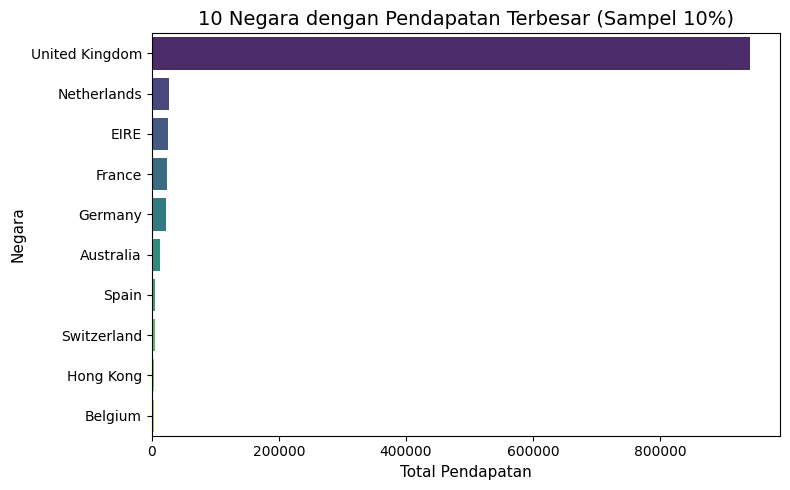

In [14]:
plt.figure(figsize=(8, 5))
sns.barplot(x=top10.values, y=top10.index, hue=top10.index,
            palette="viridis", legend=False)
plt.title("10 Negara dengan Pendapatan Terbesar (Sampel 10%)", fontsize=14)
plt.xlabel("Total Pendapatan", fontsize=11)
plt.ylabel("Negara", fontsize=11)
plt.tight_layout()
plt.show()

### Uji Keputusan: Mempertahankan atau Membuang Baris Tanpa CustomerID

Pendapatan per negara dihitung dengan dua cara: **B** mempertahankan baris tanpa CustomerID (keputusan yang dipakai), dan **A** membuangnya. Perbandingan ini menunjukkan apakah keputusan tersebut memengaruhi kesimpulan.

In [15]:
rev_b = df_bersih.groupby("Country")["Revenue"].sum()                       # pilihan B
rev_a = df_bersih.dropna(subset=["CustomerID"]).groupby("Country")["Revenue"].sum()  # pilihan A

perbandingan = pd.DataFrame({"B_pertahankan": rev_b, "A_buang": rev_a}).loc[top10.index]
perbandingan["selisih_persen"] = ((perbandingan["A_buang"] / perbandingan["B_pertahankan"] - 1) * 100).round(1)
perbandingan

,B_pertahankan,A_buang,selisih_persen
Country,,,
United Kingdom,941619.991,768682.561,-18.4
Netherlands,27435.830,27435.830,0.0
EIRE,26066.000,24340.420,-6.6
France,23645.330,23606.730,-0.2
Germany,22389.510,22389.510,0.0
Australia,12429.990,12429.990,0.0
Spain,5600.900,5600.900,0.0
Switzerland,5483.890,5383.190,-1.8
Hong Kong,3597.850,NaN,NaN


Peringkat delapan negara teratas tidak berubah pada kedua cara. Namun cara A mengurangi pendapatan United Kingdom sebesar 18,4% dan EIRE sebesar 6,6%, serta menghapus Hong Kong karena seluruh transaksinya tidak memiliki CustomerID. Karena itu baris tanpa CustomerID dipertahankan.

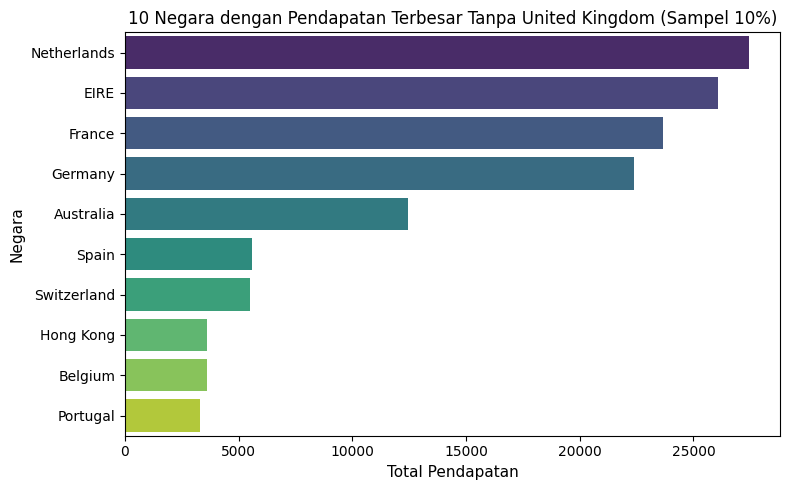

In [16]:
top10_tanpa_uk = (df_bersih[df_bersih["Country"] != "United Kingdom"]
                  .groupby("Country")["Revenue"].sum()
                  .sort_values(ascending=False).head(10))

plt.figure(figsize=(8, 5))
sns.barplot(x=top10_tanpa_uk.values, y=top10_tanpa_uk.index, hue=top10_tanpa_uk.index,
            palette="viridis", legend=False)
plt.title("10 Negara dengan Pendapatan Terbesar Tanpa United Kingdom (Sampel 10%)", fontsize=12)
plt.xlabel("Total Pendapatan", fontsize=11)
plt.ylabel("Negara", fontsize=11)
plt.tight_layout()
plt.show()

In [17]:
total = df_bersih["Revenue"].sum()
print("Total pendapatan:", round(total, 2))
print((top10 / total * 100).round(2))

Total pendapatan: 1096775.81
Country
United Kingdom    85.85
Netherlands        2.50
EIRE               2.38
France             2.16
Germany            2.04
Australia          1.13
Spain              0.51
Switzerland        0.50
Hong Kong          0.33
Belgium            0.33
Name: Revenue, dtype: float64


In [18]:
df_bersih["Country"].value_counts().head(10)

,count
Country,
United Kingdom,48465
Germany,935
France,835
EIRE,804
Spain,256
Netherlands,233
Belgium,190
Switzerland,189
Portugal,184


## Kesimpulan

United Kingdom adalah negara dengan pendapatan terbesar, yaitu sekitar 941,6 ribu pada sampel 10%, atau sekitar 85,85% dari total pendapatan (1.096.775,81). Netherlands di peringkat kedua hanya sekitar 27,4 ribu (sekitar 2,5%), disusul EIRE (Irlandia), France, dan Germany pada kisaran 22 sampai 26 ribu. United Kingdom juga mendominasi jumlah transaksi: 48.465 dari 52.995 baris (sekitar 91,5%). Hal ini sejalan dengan kenyataan bahwa toko ini berbasis di Inggris.

Netherlands dan Australia memperoleh pendapatan tinggi dari transaksi yang jauh lebih sedikit (233 dan 117 baris), dengan pendapatan per baris sekitar 118 dan 106, dibanding sekitar 19 untuk United Kingdom. Peringkat kedua negara itu karena bergantung pada sedikit transaksi bernilai besar, dan dapat berubah pada sampel yang berbeda.

Menguji keputusan untuk mempertahankan baris tanpa CustomerID menunjukkan bahwa membuangnya tidak mengubah peringkat delapan negara teratas, tetapi akan mengurangi pendapatan United Kingdom sekitar 18,4% dan menghapus Hong Kong dari daftar karena seluruh transaksinya tidak memiliki CustomerID. Karena itu baris tersebut dipertahankan.

Karena analisis memakai sampel acak 10%, jumlah nominal hanya perkiraan sekitar sepersepuluh dari data penuh. Peringkat di bagian bawah daftar (Spain sampai Belgium) dan selisih Netherlands dengan EIRE juga dapat berubah pada sampel yang berbeda.